In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import shap
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score

sys.path.insert(0, str(Path("../src").resolve()))
%load_ext autoreload
%autoreload 2

DATA = Path("../data/processed")
FIG = Path("../reports/figures")
FEATURES = [f"f{i}" for i in range(12)]

# Testset mit Merkmalen und den gespeicherten Vorhersagen aus Notebook 03
df = pd.read_parquet(DATA / "criteo_uplift_v2.1.parquet", columns=FEATURES + ["treatment", "visit"])
split = pd.read_parquet(DATA / "split.parquet")["split"].to_numpy()
te = df[split == 2]
del df
preds = pd.read_parquet(DATA / "preds_test.parquet")
assert preds.index.equals(te.index)   # gleiche Zeilen in gleicher Reihenfolge
X = te[FEATURES]

c:\Users\Xin\GitHub\data-scientist\uplift-modeling\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Surrogat-Modelle: Der S-Learner-Uplift ist eine Differenz zweier Modellaufrufe, der Causal Forest wurde
# nicht gespeichert → einheitlicher Weg: ein Modell lernt die Abbildung X → Vorhersage nach, SHAP erklärt dieses.
# Zum Vergleich dasselbe für das Response-Modell. Erklärt wird, was die Modelle gelernt haben,
# nicht direkt die Kausalstruktur.
idx = np.random.default_rng(0).permutation(len(te))
fit_idx, hold_idx, expl_idx = idx[:500_000], idx[500_000:700_000], idx[700_000:720_000]

TARGETS = ["response", "s_learner", "causal_forest"]
surrogates = {}
for m in TARGETS:
    sur = LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=63, min_child_samples=50, verbose=-1)
    sur.fit(X.iloc[fit_idx], preds[m].iloc[fit_idx])
    r2 = r2_score(preds[m].iloc[hold_idx], sur.predict(X.iloc[hold_idx]))
    print(f"{m:14s} R² des Surrogats auf ungesehenen Test-Nutzern: {r2:.3f}")
    surrogates[m] = sur

response       R² des Surrogats auf ungesehenen Test-Nutzern: 0.998
s_learner      R² des Surrogats auf ungesehenen Test-Nutzern: 0.985
causal_forest  R² des Surrogats auf ungesehenen Test-Nutzern: 1.000


In [3]:
# SHAP-Werte für 20.000 Test-Nutzer. LightGBM rechnet TreeSHAP selbst (pred_contrib=True);
# letzte Spalte = Basiswert (mittlere Vorhersage), die anderen = Beitrag je Merkmal
X_expl = X.iloc[expl_idx]
shap_vals, base = {}, {}
for m, sur in surrogates.items():
    contrib = sur.predict(X_expl, pred_contrib=True)
    shap_vals[m], base[m] = contrib[:, :-1], contrib[0, -1]

# globale Wichtigkeit: mittlerer |SHAP|, als Anteil je Modell (Response und Uplift haben verschiedene Skalen)
importance = pd.DataFrame({m: np.abs(v).mean(axis=0) for m, v in shap_vals.items()}, index=FEATURES)
importance = (importance / importance.sum()).sort_values("s_learner", ascending=False)
importance.round(3)

,response,s_learner,causal_forest
f3,0.023,0.240,0.414
f8,0.529,0.228,0.264
f6,0.048,0.172,0.067
f9,0.166,0.151,0.149
f0,0.018,0.083,0.042
f2,0.193,0.075,0.059
f4,0.005,0.022,0.000
f10,0.004,0.011,0.001
f7,0.005,0.010,0.002
f5,0.002,0.005,0.002


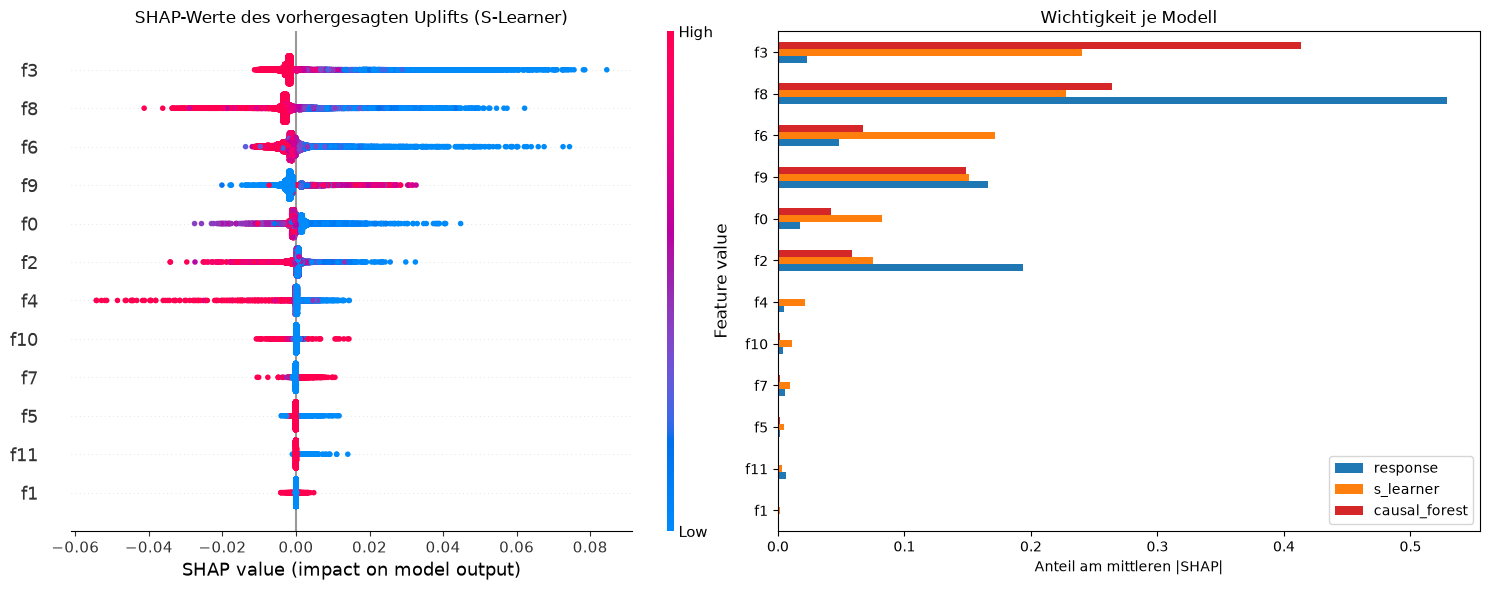

In [4]:
# Links: Beeswarm für den S-Learner (jeder Punkt ein Nutzer, Farbe = Merkmalswert)
# Rechts: Wichtigkeit im Vergleich – was treibt "wer kommt?" und was "wer reagiert auf Werbung?"
fig = plt.figure(figsize=(15, 6))
ax0 = fig.add_subplot(1, 2, 1)
shap.summary_plot(shap_vals["s_learner"], X_expl, show=False, plot_size=None, max_display=12)
ax0.set_title("SHAP-Werte des vorhergesagten Uplifts (S-Learner)")
ax1 = fig.add_subplot(1, 2, 2)
importance[::-1].plot.barh(ax=ax1, color={"response": "C0", "s_learner": "C1", "causal_forest": "C3"})
ax1.set_xlabel("Anteil am mittleren |SHAP|")
ax1.set_title("Wichtigkeit je Modell")
fig.tight_layout()
fig.savefig(FIG / "shap_uplift.png", dpi=120, bbox_inches="tight")

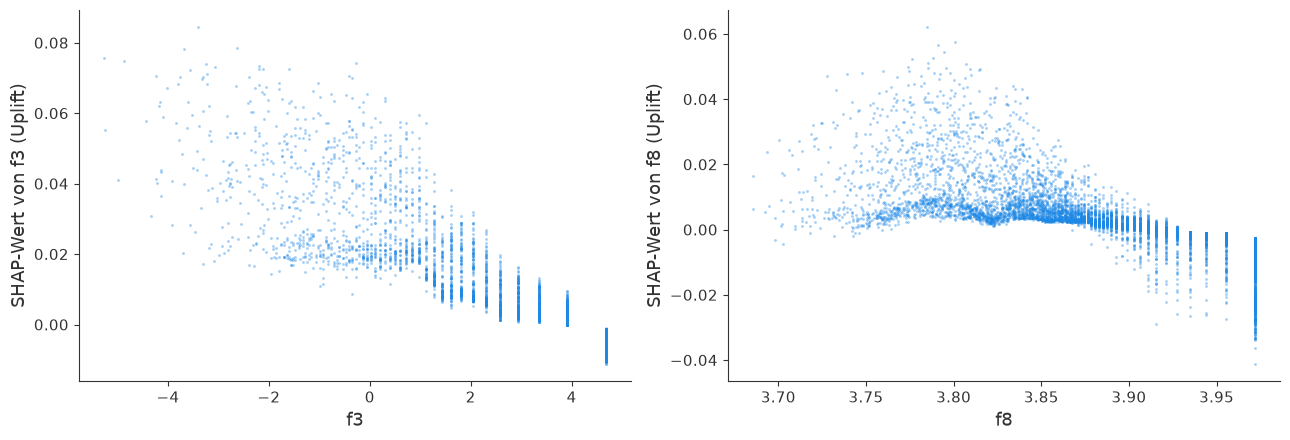

In [5]:
# Abhängigkeit: Wie verändert sich der vorhergesagte Uplift mit den zwei wichtigsten Merkmalen?
top2 = importance.index[:2].tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, f in zip(axes, top2):
    shap.dependence_plot(f, shap_vals["s_learner"], X_expl, interaction_index=None, ax=ax, show=False,
                         dot_size=4, alpha=0.4)
    ax.set_ylabel(f"SHAP-Wert von {f} (Uplift)")
fig.tight_layout()
fig.savefig(FIG / "shap_dependence.png", dpi=120, bbox_inches="tight")

In [6]:
# Gegenprobe mit den Daten (alle 2,8 Mio. Test-Nutzer): Gruppen nach Merkmalswert,
# je Gruppe beobachteter Uplift (Rate_T − Rate_C) vs. mittlere Vorhersage.
# f3 und f8 nehmen bei vielen Nutzern genau einen Wert an (zugleich ihr Höchstwert) → eigene Gruppe,
# der Rest wird in Quantilgruppen geteilt
def uplift_by_feature(f, n_bins=5):
    v = te[f]
    mode = v.mode()[0]
    rest = v != mode
    bins = pd.qcut(v[rest], n_bins, duplicates="drop")
    labels = [str(c) for c in bins.cat.categories] + [f"= {mode:.3f} (häufigster Wert)"]
    g = pd.Series(labels[-1], index=v.index)
    g[rest] = bins.astype(str)
    d = pd.DataFrame({"g": pd.Categorical(g, categories=labels, ordered=True),
                      "y": te["visit"], "w": te["treatment"],
                      "pred_s": preds["s_learner"], "pred_cf": preds["causal_forest"]})
    grp = d.groupby("g", observed=True)
    p1 = d[d.w == 1].groupby("g", observed=True)["y"].mean()
    p0 = d[d.w == 0].groupby("g", observed=True)["y"].mean()
    n1, n0 = grp["w"].sum(), grp["w"].count() - grp["w"].sum()
    return pd.DataFrame({"anteil": grp.size() / len(d), "visit_kontrolle": p0,
                         "beobachtet": p1 - p0, "ki_95": 1.96 * np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0),
                         "vorhersage_s": grp["pred_s"].mean(), "vorhersage_cf": grp["pred_cf"].mean()})

for f in top2:
    print(f"Merkmal {f}:")
    display(uplift_by_feature(f).round(4))

Merkmal f3:


,anteil,visit_kontrolle,beobachtet,ki_95,vorhersage_s,vorhersage_cf
g,,,,,,
"(-7.445, 0.295]",0.0374,0.1328,0.0906,0.0064,0.0726,0.0573
"(0.295, 1.815]",0.0377,0.0975,0.0499,0.0053,0.0365,0.0343
"(1.815, 2.935]",0.0432,0.0826,0.0296,0.0045,0.0222,0.0184
"(2.935, 3.908]",0.0633,0.0649,0.0129,0.0033,0.0123,0.0111
= 4.680 (häufigster Wert),0.8184,0.0279,0.0021,0.0006,0.0019,0.0020


Merkmal f8:


,anteil,visit_kontrolle,beobachtet,ki_95,vorhersage_s,vorhersage_cf
g,,,,,,
"(3.64, 3.84]",0.0965,0.2936,0.0465,0.0050,0.0418,0.0317
"(3.84, 3.89]",0.1004,0.0733,0.0191,0.0028,0.0192,0.0167
"(3.89, 3.921]",0.0905,0.0265,0.0068,0.0018,0.0078,0.0079
"(3.921, 3.944]",0.1216,0.0087,0.0043,0.0009,0.0027,0.0034
"(3.944, 3.955]",0.0685,0.0072,0.0024,0.0011,0.0021,0.0023
= 3.972 (häufigster Wert),0.5224,0.0009,0.0006,0.0001,0.0004,0.0010


In [7]:
importance.to_csv("../reports/shap_importance.csv")